# LM35 Lab — Stress Testing

Companion notebook to **From Calculus to Kelly, LM35**. It rebuilds the module's exhibits and computational examples from E5's frames, the through case's trades and wealth paths, TR23, the five named days of the 5-second TAIEX, TX on its limit days, the US proxies and 0050's own 2007–2008 files. It solves the computational practice problems, reproduces the widget's starting state, and ends with the batch's checkpoint on a universe of eight funds.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: E5's two frames, TR23, $T$, $A$, $A_{\mathrm w}$ |
| 2 | The scenario windows (Exhibit 2), Example 1 and LM1's running peak, the returns that span holidays |
| 3 | The rules' books rebuilt from their trades; Exhibit 1, Exhibit 3, Exhibit 4, Example 2, Example 3, problems 9 and 10 |
| 4 | The pairing rule (35.5) for US proxies; Example 4, Example 5, problem 4 |
| 5 | Betas, the partial scenario (35.3) and the correlation break: Example 6, Example 7, the check of (16.10) |
| 6 | The reverse stress test (35.4) by hand and in cvxpy with a price limit: Example 8, Exhibit 5, problem 11 |
| 7 | Exhibit 7 from the five 5-second days, Exhibit 6, Example 9, Exhibit 8, Example 10, problem 12 |
| 8 | The widget's starting state |
| 9 | **The batch's checkpoint**: allocate, compare out of sample, stress and explain, on eight funds |
| 10 | Extension: 2008 with R2's mix and with DBO |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

Part 7 also reads the five named days of the 5-second TAIEX (`taiex5s_<date>.csv`). `make_lab_data.py` copies them when `data/raw/intraday/taiex5s/` holds them, which `uv run python data/fetch_intraday.py --series taiex5s --dates 2008-01-22,2015-08-24,2020-01-30,2024-08-05,2025-04-07` fetches (five requests); without them Part 7 says so and skips Exhibit 7. The notebook writes per-day statistics only, never an intraday path.

**Conventions (as in the module).** Simple returns; covariances divide by $T$; years are calendar days / 365.25 from the base close. A frozen replay holds a book's exposures at a window's first close; a named-day replay applies the book of the previous close; an actual path is the rule's wealth ratio. Proxies: a US close takes the first USD/TWD row dated after it, and a Taiwan date takes the last US session before it. Counts against a threshold use the guard `1e-12`; quantiles `inverted_cdf`.

In [1]:
import bisect
import math
from datetime import date
from fractions import Fraction
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

DATA = Path("data")
EPS = 1e-12
RF, SPREAD, COMMISSION, CAP = 0.015, 0.02, 0.001425, 1.5
FUNDS = ["0050", "00646", "00679B", "00635U", "00642U"]
CFUNDS = FUNDS + ["0056", "00662", "00720B"]           # the checkpoint universe
TAX = {"0050": 0.001, "00646": 0.001, "00679B": 0.0, "00635U": 0.001,
       "00642U": 0.001, "0056": 0.001, "00662": 0.001, "00720B": 0.0}
RULES = [f"R{k}" for k in range(1, 9)]
CLARABEL = {"tol_gap_abs": 1e-12, "tol_gap_rel": 1e-12, "tol_feas": 1e-12}
OSQP = {"eps_abs": 1e-10, "eps_rel": 1e-10, "max_iter": 400000,
        "polishing": True}
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def pct(label, x, d, printed):
    # a return in percent: signed as the book prints it, or unsigned for a loss
    if printed[0] in "+-":
        show(label, 100 * x, f"+.{d}f", printed)
    else:
        show(label, abs(100 * x), f".{d}f", printed)


def cov0(x):
    # sample covariance, divisor T
    xc = x - x.mean(axis=0)
    return xc.T @ xc / x.shape[0]


def frames(prefix, funds):
    # a sample's estimation frame (joint one-session returns) and wealth frame (every session, traded flags)
    sch = {"fund": pl.Utf8, "base": pl.Utf8, "date": pl.Utf8}
    el = pl.read_csv(DATA / f"{prefix}_estimation.csv", schema_overrides=sch)
    wl = pl.read_csv(DATA / f"{prefix}_wealth.csv", schema_overrides=sch)
    est = el.pivot(on="fund", index="date", values="R").sort("date")
    wf = wl.pivot(on="fund", index="date", values="R").sort("date")
    tf = wl.pivot(on="fund", index="date", values="traded").sort("date")
    wd = wf["date"].to_list()
    years = (date.fromisoformat(wd[-1])
             - date.fromisoformat(el["base"][0])).days / 365.25
    return {"X": est.select(funds).to_numpy(), "est": est["date"].to_list(),
            "W": wf.select(funds).to_numpy(), "wd": wd,
            "traded": tf.select(funds).to_numpy().astype(bool),
            "base": el["base"][0], "years": years,
            "A": est.height / years, "Aw": len(wd) / years}

## Part 1 — Data

E5's estimation frame holds the dates on which every fund has a one-session return; its wealth frame holds every session, a halted fund earning 0 until it trades again. TR23 is the TAIEX total-return index.

In [2]:
E = frames("e5", FUNDS)
X, WR, wd = E["X"], E["W"], E["wd"]
WIDX = {d: i for i, d in enumerate(wd)}
show("T", len(E["est"]), ",d", "2,362")
show("A", E["A"], ".2f", "242.95")
show("wealth sessions", len(wd), ",d", "2,368")
show("A_w", E["Aw"], ".2f", "243.57")
show("years", E["years"], ".2f", "9.72")
tr = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"date": pl.Utf8})
tr = tr.sort("date")
TD = tr["date"].to_list()
LV = tr["price"].to_numpy()
RT = np.r_[np.nan, LV[1:] / LV[:-1] - 1]
TPOS = {d: i for i, d in enumerate(TD)}
show("TR23 returns", len(TD) - 1, ",d", "5,849")

T: 2,362   [book: 2,362]
A: 242.95   [book: 242.95]
wealth sessions: 2,368   [book: 2,368]
A_w: 243.57   [book: 243.57]
years: 9.72   [book: 9.72]
TR23 returns: 5,849   [book: 5,849]


## Part 2 — Scenario windows

The trough is TR23's lowest close of the named year, or of the 20 sessions from the named day; the peak is the highest close after the previous scenario's trough. A span of $m$ sessions is dated from the close before its first return.

In [3]:
SCEN = [("2008", "year"), ("2015", "year"), ("2020", "year"),
        ("2024-08-05", "day"), ("2025-04-07", "day")]
WIN, WORST = {}, {}
prev = -1
for name, kind in SCEN:
    if kind == "year":
        idx = [i for i, d in enumerate(TD) if d[:4] == name]
        k = idx[0] + int(np.argmin(LV[idx[0]:idx[-1] + 1]))
    else:
        k = TPOS[name] + int(np.argmin(LV[TPOS[name]:TPOS[name] + 20]))
    p = prev + 1 + int(np.argmax(LV[prev + 1:k + 1]))
    nd = p + 1 + int(np.argmin(RT[p + 1:k + 1]))
    WORST[name] = {m: min((LV[j] / LV[j - m] - 1, j) for j in range(p + 1, k + 1))
                   for m in (5, 20)}
    WIN[name] = (TD[p], TD[k], TD[nd])
    rank = int((RT[1:] < RT[nd] - EPS).sum()) + 1
    print(f"{name}: peak {TD[p]}, trough {TD[k]}, {k - p} sessions; worst day "
          f"{TD[nd]} {100 * RT[nd]:.2f}% (rank {rank}); worst 5 "
          f"{100 * WORST[name][5][0]:.2f}%, worst 20 {100 * WORST[name][20][0]:.2f}%,"
          f" peak to trough {100 * (LV[k] / LV[p] - 1):.2f}%")
    prev = k
pct("2008 peak to trough", LV[TPOS[WIN["2008"][1]]] / LV[TPOS[WIN["2008"][0]]] - 1,
    2, "56.02")
pct("2025 worst 5 sessions", WORST["2025-04-07"][5][0], 2, "15.96")
pct("2025 worst 20 sessions", WORST["2025-04-07"][20][0], 2, "22.38")
k25 = TPOS["2025-04-09"]
print("running peak", TD[int(np.argmax(LV[:k25 + 1]))])
pct("LM1's DD on 9 April 2025", 1 - LV[k25] / LV[:k25 + 1].max(), 2, "27.72")
gaps = np.array([(date.fromisoformat(TD[i]) - date.fromisoformat(TD[i - 1])).days
                 for i in range(1, len(TD))])
long_ = gaps >= 4
show("returns spanning 4+ days", int(long_.sum()), "d", "140")
pct("their mean |R|", np.abs(RT[1:][long_]).mean(), 2, "1.39")
pct("the rest", np.abs(RT[1:][~long_]).mean(), 2, "0.83")

2008: peak 2007-10-29, trough 2008-11-20, 265 sessions; worst day 2008-01-22 -6.51% (rank 4); worst 5 -12.55%, worst 20 -27.69%, peak to trough -56.02%
2015: peak 2015-04-27, trough 2015-08-24, 82 sessions; worst day 2015-08-24 -4.82% (rank 17); worst 5 -9.72%, worst 20 -12.49%, peak to trough -23.18%
2020: peak 2020-01-14, trough 2020-03-19, 39 sessions; worst day 2020-01-30 -5.75% (rank 8); worst 5 -16.51%, worst 20 -25.99%, peak to trough -28.55%
2024-08-05: peak 2024-07-11, trough 2024-08-05, 15 sessions; worst day 2024-08-05 -8.33% (rank 2); worst 5 -10.44%, worst 20 -15.14%, peak to trough -18.31%
2025-04-07: peak 2025-02-21, trough 2025-04-09, 30 sessions; worst day 2025-04-07 -9.70% (rank 1); worst 5 -15.96%, worst 20 -22.38%, peak to trough -26.54%
2008 peak to trough: 56.02   [book: 56.02]
2025 worst 5 sessions: 15.96   [book: 15.96]
2025 worst 20 sessions: 22.38   [book: 22.38]
running peak 2024-07-11
LM1's DD on 9 April 2025: 27.72   [book: 27.72]
returns spanning 4+ days: 

## Part 3 — The rules' books and the replays

Each rule's exposures are rebuilt day by day from its stored trades (targets and cost over pre-trade wealth), with the wealth frame's returns, cash at 1.5% and borrowing at 3.5% a year accrued per session, and checked against the stored net wealth to $10^{-12}$.

In [4]:
tg = pl.read_csv(DATA / "rule_targets.csv",
                 schema_overrides={"rule": pl.Utf8, "signal": pl.Utf8, "trade": pl.Utf8})
nw = pl.read_csv(DATA / "rule_wealth_net.csv",
                 schema_overrides={"rule": pl.Utf8, "date": pl.Utf8})


def book(rule):
    t = tg.filter(pl.col("rule") == rule).sort("trade")
    tgt = {r["trade"]: (np.array([r[s] for s in FUNDS]), r["cost"])
           for r in t.iter_rows(named=True)}
    i0 = WIDX[t["trade"][0]]
    h, c = np.zeros(len(FUNDS)), 1.0
    ex, ws, pre = [], [], {}
    for i in range(i0, len(wd)):
        if i > i0:
            h = h * (1 + WR[i])
            c *= 1 + (RF if c >= 0 else RF + SPREAD) / E["Aw"]
        w = h.sum() + c
        if wd[i] in tgt:
            pre[wd[i]] = h / w
            f, cost = tgt[wd[i]]
            w *= 1 - cost
            h, c = w * f, w * (1 - f.sum())
        ex.append(h / w)
        ws.append(w)
    ref = nw.filter(pl.col("rule") == rule).sort("date")["wealth"].to_numpy()
    assert np.abs(np.array(ws) / ref - 1).max() < 1e-12
    return {"d": {d: k for k, d in enumerate(wd[i0:])}, "ex": np.array(ex),
            "w": np.array(ws), "pre": pre}


B = {k: book(k) for k in RULES}


def expo(rule, d):
    return B[rule]["ex"][B[rule]["d"][d]]


def wealth(rule, d):
    return B[rule]["w"][B[rule]["d"][d]]


def growth(a, b):
    # each fund's compound wealth-frame return over (a, b]
    return np.prod(1 + WR[WIDX[a] + 1:WIDX[b] + 1], axis=0) - 1


print("every rebuilt book equals the stored wealth to 1e-12")
w7 = WR[WIDX["2025-04-07"]]
day7 = {k: float(expo(k, "2025-04-02") @ w7) for k in RULES}
for k, p in zip(RULES, ["7.70", "6.29", "5.40", "8.33", "5.39", "5.96", "5.06",
                        "7.94"], strict=True):
    pct(f"{k} on 7 April 2025", day7[k], 2, p)
show("R8's exposure on 2 April", expo("R8", "2025-04-02").sum(), ".3f", "1.331")

every rebuilt book equals the stored wealth to 1e-12
R1 on 7 April 2025: 7.70   [book: 7.70]
R2 on 7 April 2025: 6.29   [book: 6.29]
R3 on 7 April 2025: 5.40   [book: 5.40]
R4 on 7 April 2025: 8.33   [book: 8.33]
R5 on 7 April 2025: 5.39   [book: 5.39]
R6 on 7 April 2025: 5.96   [book: 5.96]
R7 on 7 April 2025: 5.06   [book: 5.06]
R8 on 7 April 2025: 7.94   [book: 7.94]
R8's exposure on 2 April: 1.331   [book: 1.331]


shape: (9, 9)
┌─────────────────┬────────┬────────┬────────┬───┬────────┬────────┬────────┬────────┐
│ scenario        ┆ R1     ┆ R2     ┆ R3     ┆ … ┆ R5     ┆ R6     ┆ R7     ┆ R8     │
│ ---             ┆ ---    ┆ ---    ┆ ---    ┆   ┆ ---    ┆ ---    ┆ ---    ┆ ---    │
│ str             ┆ f64    ┆ f64    ┆ f64    ┆   ┆ f64    ┆ f64    ┆ f64    ┆ f64    │
╞═════════════════╪════════╪════════╪════════╪═══╪════════╪════════╪════════╪════════╡
│ 2020, frozen    ┆ -19.84 ┆ -15.33 ┆ -10.17 ┆ … ┆ -10.33 ┆ -13.04 ┆ -10.22 ┆ -17.04 │
│ 2020, actual    ┆ -21.44 ┆ -16.21 ┆ -11.34 ┆ … ┆ -11.53 ┆ -14.43 ┆ -11.78 ┆ -12.58 │
│ 2020, named day ┆ -1.6   ┆ -0.85  ┆ 0.91   ┆ … ┆ 0.86   ┆ 0.07   ┆ 0.69   ┆ 0.09   │
│ 2024, frozen    ┆ -5.84  ┆ -7.69  ┆ 0.11   ┆ … ┆ -0.07  ┆ -3.25  ┆ -3.8   ┆ -3.61  │
│ 2024, actual    ┆ -5.99  ┆ -7.87  ┆ 0.11   ┆ … ┆ -0.09  ┆ -3.42  ┆ -3.95  ┆ -3.5   │
│ 2024, named day ┆ -2.99  ┆ -3.41  ┆ -0.51  ┆ … ┆ -0.59  ┆ -1.92  ┆ -2.16  ┆ -1.92  │
│ 2025, frozen    ┆ -12.97 ┆ 

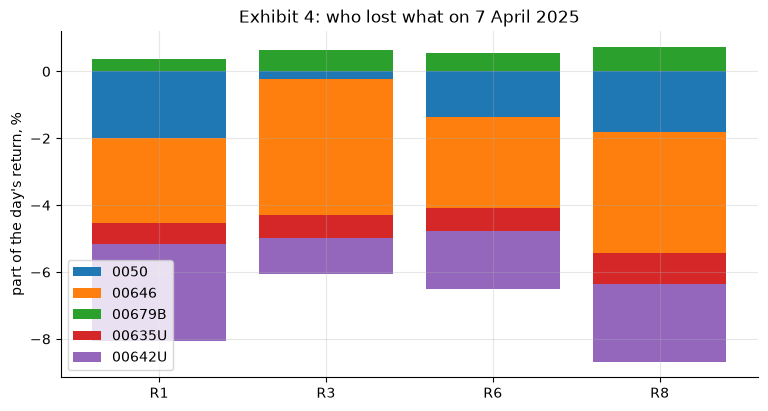

In [5]:
FZ, AC, ND = {}, {}, {}
for n in ("2020", "2024-08-05", "2025-04-07"):
    a, b, nd = WIN[n]
    g = growth(a, b)
    eve = wd[WIDX[nd] - 1]
    FZ[n] = {k: float(expo(k, a) @ g) for k in RULES}
    AC[n] = {k: wealth(k, b) / wealth(k, a) - 1 for k in RULES}
    ND[n] = {k: float(expo(k, eve) @ WR[WIDX[nd]]) for k in RULES}
rows = [{"scenario": f"{n[:4]}, {lab}",
         **{k: round(100 * src[n][k], 2) for k in RULES}}
        for n in FZ for lab, src in (("frozen", FZ), ("actual", AC), ("named day", ND))]
print(pl.DataFrame(rows))
pct("R1 frozen 2020", FZ["2020"]["R1"], 2, "-19.84")
pct("R8 actual 2025", AC["2025-04-07"]["R8"], 2, "-13.84")
parts = {k: expo(k, "2025-04-02") * w7 for k in ("R1", "R3", "R6", "R8")}
for j, p in enumerate(["-2.00", "-2.53", "+0.36", "-0.62", "-2.91"]):
    pct(f"R1's part from {FUNDS[j]}", parts["R1"][j], 2, p)
fig, ax = plt.subplots()
bottom_p, bottom_n = np.zeros(4), np.zeros(4)
for j, s in enumerate(FUNDS):
    v = np.array([100 * parts[k][j] for k in parts])
    ax.bar(list(parts), v, bottom=np.where(v >= 0, bottom_p, bottom_n), label=s)
    bottom_p += np.maximum(v, 0)
    bottom_n += np.minimum(v, 0)
ax.set_ylabel("part of the day's return, %")
ax.set_title("Exhibit 4: who lost what on 7 April 2025")
ax.legend()
plt.show()

**Example 3 and problem 10.** R8's trades into the windows, each post-trade book frozen over the whole window; then R6's and R8's gaps between path and frozen book, explained trade by trade: the change of exposures at each trade times each fund's return from that trade to the trough.

In [6]:
r8 = tg.filter(pl.col("rule") == "R8").sort("trade")["trade"].to_list()
g20 = growth(*WIN["2020"][:2])
g25 = growth(*WIN["2025-04-07"][:2])
show("R8 entry 2020", expo("R8", WIN["2020"][0]).sum(), ".3f", "1.307")
pct("book of 3 Feb 2020", float(expo("R8", "2020-02-03") @ g20), 2, "13.20")
pct("book of 2 Mar 2020", float(expo("R8", "2020-03-02") @ g20), 2, "11.68")
show("R8 after 3 March 2025", expo("R8", "2025-03-03").sum(), ".3f", "1.319")
pct("book of 3 Mar 2025", float(expo("R8", "2025-03-03") @ g25), 2, "13.35")
eff = {}
for k in ("R6", "R8"):
    a, b, _ = WIN["2020"]
    eff[k] = []
    for d in [x for x in r8 if a < x <= b]:
        dl = expo(k, d) - B[k]["pre"][d]
        eff[k].append(float(dl @ growth(d, b)))
        print(k, d, "bought", [FUNDS[j] for j in range(5) if dl[j] > 0],
              f"effect {100 * eff[k][-1]:+.2f} points")
    print(f"{k}: path {100 * AC['2020'][k]:.2f}%, frozen {100 * FZ['2020'][k]:.2f}%, "
          f"gap {100 * (AC['2020'][k] - FZ['2020'][k]):+.2f}, trades {100 * sum(eff[k]):+.2f}")
pct("R6's trade of 3 February", eff["R6"][0], 2, "0.90")
pct("R6's trade of 2 March", eff["R6"][1], 2, "0.47")
pct("R8's trade of 3 February", eff["R8"][0], 2, "3.41")
pct("R8's trade of 2 March", eff["R8"][1], 2, "1.10")

R8 entry 2020: 1.307   [book: 1.307]
book of 3 Feb 2020: 13.20   [book: 13.20]
book of 2 Mar 2020: 11.68   [book: 11.68]
R8 after 3 March 2025: 1.319   [book: 1.319]
book of 3 Mar 2025: 13.35   [book: 13.35]
R6 2020-02-03 bought ['0050', '00646', '00642U'] effect -0.90 points
R6 2020-03-02 bought ['0050', '00646', '00642U'] effect -0.47 points
R6: path -14.43%, frozen -13.04%, gap -1.40, trades -1.37
R8 2020-02-03 bought [] effect +3.41 points
R8 2020-03-02 bought [] effect +1.10 points
R8: path -12.58%, frozen -17.04%, gap +4.46, trades +4.51
R6's trade of 3 February: 0.90   [book: 0.90]
R6's trade of 2 March: 0.47   [book: 0.47]
R8's trade of 3 February: 3.41   [book: 3.41]
R8's trade of 2 March: 1.10   [book: 1.10]


## Part 4 — Proxies and the pairing rule (35.5)

A US close takes the mid of the first USD/TWD row dated after it; a Taiwan date takes the last US session before it, so its return compounds every US session since the previous Taiwan date.

In [7]:
WINDOW = "2007-07-02__2026-10-08"
fx = pl.read_csv(DATA / f"USD_TWD__{WINDOW}.csv", schema_overrides={"date": pl.Utf8})
fxd = fx["date"].to_list()
fxm = (fx["spot_buy"].to_numpy() + fx["spot_sell"].to_numpy()) / 2
ADJ = {}
for s in ("SPY", "TLT", "GLD", "USO", "DBO"):
    df = pl.read_csv(DATA / f"{s}__us_{WINDOW}.csv", schema_overrides={"date": pl.Utf8})
    usd = df["date"].to_list()
    ADJ[s] = df["adj_close"].to_numpy()
rate = np.array([fxm[j] if (j := bisect.bisect_right(fxd, d)) < len(fxd) else np.nan
                 for d in usd])
PV = {s: a * rate for s, a in ADJ.items()}
LASTD = np.array([bisect.bisect_left(usd, d) - 1 for d in TD])


def prox(s, a, b):
    return float(PV[s][LASTD[TPOS[b]]] / PV[s][LASTD[TPOS[a]]] - 1)


i0 = TPOS["2007-07-03"]
ns = np.diff(LASTD)[i0 - 1:]
# how many new US sessions each Taiwan date carries (the module does not print
# these counts; a date with none gives every proxy a return of exactly 0)
counts = [int((ns == 0).sum()), int((ns == 1).sum()), int((ns == 2).sum()),
          int((ns >= 3).sum())]
print(f"TR23 dates from 3 July 2007: {len(ns):,d}; new US sessions per date: "
      f"none {counts[0]}, one {counts[1]:,d}, two {counts[2]}, "
      f"three or more {counts[3]}")

TR23 dates from 3 July 2007: 4,736; new US sessions per date: none 170, one 4,421, two 94, three or more 51


In [8]:
px = pl.read_csv(DATA / "0050__2007-07-02__2008-12-31.csv", schema_overrides={"date": pl.Utf8})
dv = pl.read_csv(DATA / "0050_dividends__2007-07-02__2008-12-31.csv",
                 schema_overrides={"date": pl.Utf8})
div = {d: (Fraction(str(b)), Fraction(str(c)))
       for d, b, c in dv.select("date", "before_price", "cash_dividend").iter_rows()}
ds = px["date"].to_list()
cl = [Fraction(str(x)) for x in px["close"].to_list()]
sp = [Fraction(str(x)) for x in px["spread"].to_list()]
R50 = {}
for i in range(1, len(ds)):
    dd = div.get(ds[i])
    assert (dd is None and cl[i] - cl[i - 1] == sp[i]) or (dd is not None
                                                         and dd[0] == cl[i - 1])
    R50[ds[i]] = float((cl[i] + (dd[1] if dd else 0)) / cl[i - 1] - 1)
a8, b8, nd8 = WIN["2008"]
g50 = np.prod([1 + R50[d] for d in TD if a8 < d <= b8]) - 1
pct("0050 itself in 2008", g50, 2, "55.66")
first = {k: np.array([tg.filter(pl.col("rule") == k).sort("trade").row(0, named=True)[s]
                      for s in FUNDS]) for k in RULES}
ret08 = {oil: np.array([g50, prox("SPY", a8, b8), prox("TLT", a8, b8),
                        prox("GLD", a8, b8), prox(oil, a8, b8)]) for oil in ("USO", "DBO")}
for s in ("SPY", "TLT", "GLD", "USO", "DBO"):
    # a cent in each adjusted close moves the return by about (1 + R) 0.01 (1/P_a + 1/P_b):
    # print whole percents when that could move the first decimal, as the module does
    pa, pb = ADJ[s][LASTD[TPOS[a8]]], ADJ[s][LASTD[TPOS[b8]]]
    x8 = prox(s, a8, b8)
    u8 = (1 + x8) * 0.01 * (1 / pa + 1 / pb)
    d8 = 0 if round(1000 * (x8 - u8)) != round(1000 * (x8 + u8)) else 1
    print(f"{s}: {100 * x8:+.{d8}f}% in TWD")
pct("R1, USO", float(first["R1"] @ ret08["USO"]), 1, "24.5")
pct("R2", float(first["R2"] @ ret08["USO"]), 1, "25.9")
pct("R2 on 22 January 2008", 0.4 * R50["2008-01-22"], 1, "2.8")
assert LASTD[TPOS["2008-01-22"]] == LASTD[TPOS["2008-01-21"]]

0050 itself in 2008: 55.66   [book: 55.66]
SPY: -44% in TWD
TLT: +19% in TWD
GLD: -4.1% in TWD
USO: -37.3% in TWD
DBO: -27% in TWD
R1, USO: 24.5   [book: 24.5]
R2: 25.9   [book: 25.9]
R2 on 22 January 2008: 2.8   [book: 2.8]


In [9]:
ci = [TPOS[d] for d in E["est"]]
wi = [TPOS[d] for d in wd]


def weeks(dates, x, traded):
    # ISO weeks; the first and last dropped, and every week in which a fund
    # lacks a close at its end or at the end of the week before
    keys = [date.fromisoformat(d).isocalendar()[:2] for d in dates]
    uk = sorted(set(keys))
    acc = {k: np.ones(x.shape[1]) for k in uk}
    last = {}
    for i, (k, r) in enumerate(zip(keys, x, strict=True)):
        acc[k] = acc[k] * (1 + r)
        last[k] = i
    kept = [k for n, k in enumerate(uk[1:-1], 1)
            if traded[last[uk[n - 1]]].all() and traded[last[k]].all()]
    return np.array([acc[k] - 1 for k in kept])


for fund, s in (("00646", "SPY"), ("00679B", "TLT"), ("00635U", "GLD"),
                ("00642U", "USO"), ("00642U", "DBO")):
    j = FUNDS.index(fund)
    rd_ = np.array([PV[s][LASTD[i]] / PV[s][LASTD[i - 1]] - 1 for i in ci])
    rw = np.array([PV[s][LASTD[i]] / PV[s][LASTD[i - 1]] - 1 for i in wi])
    wk = weeks(wd, np.column_stack([rw, WR[:, j]]), E["traded"])
    print(f"{fund}~{s}: daily {np.corrcoef(rd_, X[:, j])[0, 1]:.3f}, "
          f"weekly {np.corrcoef(wk[:, 0], wk[:, 1])[0, 1]:.3f} over {len(wk)} weeks")
pct("problem 4", 1.01 * 0.96 * 32.48 / 32.00 - 1, 2, "-1.59")
z = np.array([LASTD[TPOS[d]] == LASTD[TPOS[d] - 1] for d in E["est"]])
show("dates without a US session", int(z.sum()), "d", "80")
pct("00646 on them", np.abs(X[z, 1]).mean(), 2, "0.43")

00646~SPY: daily 0.705, weekly 0.944 over 498 weeks
00679B~TLT: daily 0.783, weekly 0.952 over 498 weeks
00635U~GLD: daily 0.745, weekly 0.926 over 498 weeks
00642U~USO: daily 0.655, weekly 0.845 over 498 weeks
00642U~DBO: daily 0.696, weekly 0.894 over 498 weeks
problem 4: -1.59   [book: -1.59]
dates without a US session: 80   [book: 80]
00646 on them: 0.43   [book: 0.43]


## Part 5 — Betas, the partial scenario and the correlation break

In [10]:
rt_est = RT[ci]
xc = rt_est - rt_est.mean()
beta = np.array([(X[:, j] - X[:, j].mean()) @ xc / (xc @ xc) for j in range(5)])
for j, p in enumerate(["1.048", "0.527", "-0.071", "0.161", "0.198"]):
    show(f"beta {FUNDS[j]}", beta[j], ".3f", p)
pred = beta * RT[TPOS["2025-04-07"]]
pct("R1 by the beta model", float(expo("R1", "2025-04-02") @ pred), 2, "3.62")
MU, S = X.mean(axis=0), cov0(X)
SI = np.linalg.inv(S)
CUR = {k: B[k]["ex"][-1] for k in RULES}
pct("factor shock, R4", float(CUR["R4"] @ (beta * -0.10)), 2, "7.28")


def cond(Sg, x0):
    # (35.3) fund by fund, 0050 fixed at x0
    return MU + Sg[:, 0] / Sg[0, 0] * (x0 - MU[0])


sd = np.sqrt(np.diag(S))
C = S / np.outer(sd, sd)
C[0, 2] = C[2, 0] = 0.30
show("smallest eigenvalue after the break", np.linalg.eigvalsh(C).min(), ".3f", "0.298")
full, brk = cond(S, -0.10), cond(C * np.outer(sd, sd), -0.10)
pct("00679B, full", full[2], 2, "+0.71")
pct("00679B, break", brk[2], 2, "-2.04")
pct("R3 under the break", float(CUR["R3"] @ brk), 2, "2.95")
s0 = X[:, 0].std(ddof=0)
ev = X[:, 0] <= MU[0] - 2 * s0 + EPS
rho = np.corrcoef(X[:, 0], X[:, 1])[0, 1]
vr_ = X[ev, 0].var(ddof=0) / s0**2
model = rho / math.sqrt(rho**2 + (1 - rho**2) / vr_)
show("tail days", int(ev.sum()), "d", "48")
show("variance ratio", vr_, ".3f", "1.449")
show("tail correlation", np.corrcoef(X[ev, 0], X[ev, 1])[0, 1], ".3f", "0.540")
show("(16.10)", model, ".3f", "0.669")

beta 0050: 1.048   [book: 1.048]
beta 00646: 0.527   [book: 0.527]
beta 00679B: -0.071   [book: -0.071]
beta 00635U: 0.161   [book: 0.161]
beta 00642U: 0.198   [book: 0.198]
R1 by the beta model: 3.62   [book: 3.62]
factor shock, R4: 7.28   [book: 7.28]
smallest eigenvalue after the break: 0.298   [book: 0.298]
00679B, full: +0.71   [book: +0.71]
00679B, break: -2.04   [book: -2.04]
R3 under the break: 2.95   [book: 2.95]
tail days: 48   [book: 48]
variance ratio: 1.449   [book: 1.449]
tail correlation: 0.540   [book: 0.540]
(16.10): 0.669   [book: 0.669]


## Part 6 — The reverse stress test (35.4)

By hand from the closed form, then with 0050's limit in cvxpy (both solvers, the objective as `quad_form` of $\hat\Sigma^{-1}$ with `psd_wrap`, percent units), checked by the KKT conditions (29.4).

In [11]:
for k, p in (("R1", "13.52"), ("R4", "9.91"), ("R8", "12.27")):
    e = CUR[k]
    show(f"{k} d*", (0.10 + e @ MU) / math.sqrt(e @ S @ e), ".2f", p)
e = CUR["R1"]
xs = MU - (0.10 + e @ MU) * (S @ e) / (e @ S @ e)
pct("R1's 00642U shock", xs[4], 2, "-23.00")
dist = np.sqrt(np.einsum("ij,jk,ik->i", X - MU, SI, X - MU))
show("largest distance", dist.max(), ".3f", "15.017")
show("median", np.quantile(dist, 0.5, method="inverted_cdf"), ".2f", "1.60")
S100, M100 = 1e4 * S, 100 * MU
Si100 = np.linalg.inv(S100)
Si100 = (Si100 + Si100.T) / 2


def bounded(e, lims=(0,)):
    sols, duals = [], None
    for solver, opts in ((cp.CLARABEL, CLARABEL), (cp.OSQP, OSQP)):
        x = cp.Variable(len(e))
        cons = [e @ x <= -10.0] + [x[j] >= -10.0 for j in lims]
        d2 = cp.quad_form(x - M100, cp.psd_wrap(Si100))
        prob = cp.Problem(cp.Minimize(d2), cons)
        prob.solve(solver=solver, **opts)
        assert prob.status == "optimal" and x.value is not None
        sols.append(x.value)
        if solver == cp.CLARABEL:
            duals = [float(c.dual_value) for c in cons]
    grad = 2 * Si100 @ (sols[0] - M100) + duals[0] * e
    for j, nu in zip(lims, duals[1:], strict=True):
        grad = grad - nu * np.eye(len(e))[j]
    zz = sols[0] - M100
    return (sols[0], math.sqrt(zz @ Si100 @ zz), duals, np.abs(grad).max(),
            np.abs(sols[0] - sols[1]).max())


x2, d2_, nu2, kkt2, gap2 = bounded(CUR["R2"])
show("problem 11: d", d2_, ".2f", "17.01")
show("problem 11: 00679B", x2[2], ".2f", "-9.89")
show("multiplier of the loss", nu2[0], ".1f", "90.3")
show("multiplier of the limit", nu2[1], ".1f", "32.7")
print(f"stationarity residual {kkt2:.1e}, OSQP gap {gap2:.1e}")
assert kkt2 < 1e-9 and gap2 < 1e-7

R1 d*: 13.52   [book: 13.52]
R4 d*: 9.91   [book: 9.91]
R8 d*: 12.27   [book: 12.27]
R1's 00642U shock: -23.00   [book: -23.00]
largest distance: 15.017   [book: 15.017]
median: 1.60   [book: 1.60]
problem 11: d: 17.01   [book: 17.01]
problem 11: 00679B: -9.89   [book: -9.89]
multiplier of the loss: 90.3   [book: 90.3]
multiplier of the limit: 32.7   [book: 32.7]
stationarity residual 1.4e-14, OSQP gap 5.8e-12


## Part 7 — Gaps, limits, locks, ruin and margin

In [12]:
days = ["2008-01-22", "2015-08-24", "2020-01-30", "2024-08-05", "2025-04-07"]
if all((DATA / f"taiex5s_{d}.csv").exists() for d in days):
    for d in days:
        t5 = pl.read_csv(DATA / f"taiex5s_{d}.csv", schema_overrides={"date": pl.Utf8})
        tt = [x[11:] for x in t5["date"].to_list()]
        v = t5["TAIEX"].to_numpy()
        p0 = v[tt.index("09:00:00")]                 # the previous close
        after = np.array([x > "09:00:00" for x in tt])
        kl = int(np.argmin(np.where(after, v, np.inf)))
        gap = math.log(v[tt.index("09:01:00")] / p0)
        close = math.log(v[tt.index("13:30:00")] / p0)
        print(f"{d}: to 09:01:00 {100 * gap:.2f}%, low {100 * math.log(v[kl] / p0):.2f}% "
              f"at {tt[kl]}, close {100 * close:.2f}%, gap / close {gap / close:.2f}")
    show("7 April 2025 daily open (09:00:05)",
         100 * math.log(v[tt.index("09:00:05")] / p0), ".2f", "-5.52")
else:
    print("no taiex5s_<date>.csv files in data/: Part 7 skips the 5-second statistics")
for j, s in enumerate(FUNDS):
    w = WR[:, j]
    print(f"{s}: lowest {100 * w.min():+.2f}%, highest {100 * w.max():+.2f}%, "
          f"days beyond 10%: {int((np.abs(w) > 0.10 + EPS).sum())}")
ohlc = pl.read_csv(DATA / "ohlc_0050_0056_00720B.csv",
                   schema_overrides={"fund": pl.Utf8, "date": pl.Utf8})
r = ohlc.filter((pl.col("fund") == "0050") & (pl.col("date") == "2025-04-07")).row(0, named=True)
assert r["open"] == r["max"] == r["min"] == r["close"] == 158.4
assert Fraction("158.40") / Fraction("176.00") - 1 == Fraction(-1, 10)
show("0050 volume", r["volume"], ",d", "29,578,872")
o8 = ohlc.filter((pl.col("fund") == "0050") & (pl.col("date") == "2025-04-08"))["open"][0]
pct("next open below the lock", o8 / 158.4 - 1, 2, "4.55")
pct("next open below 2 April", o8 / 176.0 - 1, 2, "14.09")
show("ruin leverage at the next open", -1 / (o8 / 176.0 - 1), ".2f", "7.10")
c631 = pl.read_csv(DATA / "00631L_daily_raw.csv", schema_overrides={"date": pl.Utf8})
cc = dict(c631.select("date", "close").iter_rows())
pct("00631L on 7 April", cc["2025-04-07"] / cc["2025-04-02"] - 1, 3, "19.995")
tx = pl.read_csv(DATA / "tx23_limit_days.csv", schema_overrides={"date": pl.Utf8})
t7 = tx.filter(pl.col("date") == "2025-04-07").row(0, named=True)
pct("TX on 7 April", math.exp(t7["rF"]) - 1, 2, "10.00")
show("TX volume", t7["volume"], ",d", "2,736")

2008-01-22: to 09:01:00 -6.56%, low -6.94% at 12:50:00, close -6.74%, gap / close 0.97
2015-08-24: to 09:01:00 -1.66%, low -7.79% at 10:25:45, close -4.96%, gap / close 0.34
2020-01-30: to 09:01:00 -3.48%, low -5.95% at 13:25:00, close -5.92%, gap / close 0.59
2024-08-05: to 09:01:00 -5.07%, low -8.96% at 13:03:10, close -8.72%, gap / close 0.58
2025-04-07: to 09:01:00 -10.28%, low -10.31% at 09:00:20, close -10.20%, gap / close 1.01
7 April 2025 daily open (09:00:05): -5.52   [book: -5.52]
0050: lowest -10.00%, highest +10.00%, days beyond 10%: 0
00646: lowest -12.59%, highest +10.39%, days beyond 10%: 2
00679B: lowest -7.15%, highest +8.57%, days beyond 10%: 0
00635U: lowest -11.09%, highest +7.74%, days beyond 10%: 1
00642U: lowest -22.20%, highest +33.10%, days beyond 10%: 14
0050 volume: 29,578,872   [book: 29,578,872]
next open below the lock: 4.55   [book: 4.55]
next open below 2 April: 14.09   [book: 14.09]
ruin leverage at the next open: 7.10   [book: 7.10]
00631L on 7 April: 

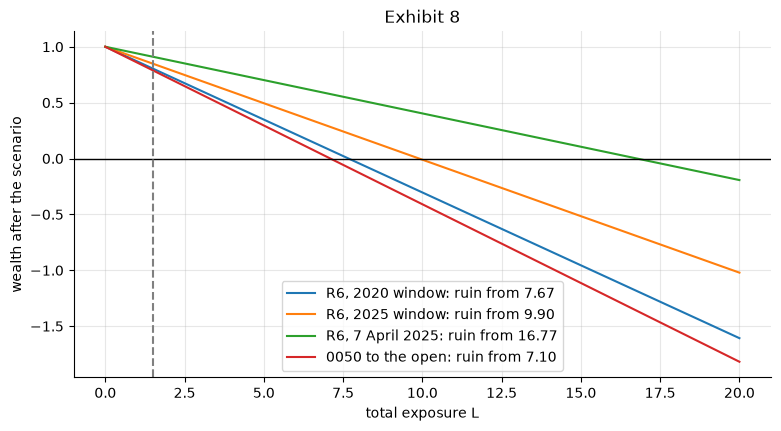

R6's 2020 ruin leverage: 7.67   [book: 7.67]
TX notional: 9,871,400   [book: 9,871,400]
f on the initial margin: 14.08   [book: 14.08]
fall to the maintenance margin: 1.65   [book: 1.65]
problem 12: f: 7.04   [book: 7.04]
problem 12: fall to the call: 8.75   [book: 8.75]
problem 12: equity after a limit day: 414,860   [book: 414,860]


In [13]:
lines = {"R6, 2020 window": FZ["2020"]["R6"], "R6, 2025 window": FZ["2025-04-07"]["R6"],
         "R6, 7 April 2025": ND["2025-04-07"]["R6"], "0050 to the open": o8 / 176.0 - 1}
L = np.linspace(0, 20, 201)
fig, ax = plt.subplots()
for nm, rr in lines.items():
    ax.plot(L, 1 + L * rr, label=f"{nm}: ruin from {-1 / rr:.2f}")
ax.axhline(0, color="k", lw=1)
ax.axvline(1.5, ls="--", color="grey")
ax.set_xlabel("total exposure L")
ax.set_ylabel("wealth after the scenario")
ax.set_title("Exhibit 8")
ax.legend()
plt.show()
show("R6's 2020 ruin leverage", -1 / FZ["2020"]["R6"], ".2f", "7.67")
F = tx.filter(pl.col("date") == "2026-10-08")["F"][0]
notional = 200 * F
show("TX notional", notional, ",.0f", "9,871,400")
show("f on the initial margin", notional / 701_000, ".2f", "14.08")
pct("fall to the maintenance margin", 163_000 / notional, 2, "1.65")
show("problem 12: f", notional / 1_402_000, ".2f", "7.04")
pct("problem 12: fall to the call", (1_402_000 - 538_000) / notional, 2, "8.75")
show("problem 12: equity after a limit day", 1_402_000 - 0.10 * notional, ",.0f", "414,860")

## Part 8 — The widget's starting state

R1's current book (8 October 2026) under the returns of 7 April 2025 at total exposure 1.

In [14]:
u1 = CUR["R1"] / CUR["R1"].sum()
r49 = float(u1 @ w7)
pct("loss", r49, 2, "7.78")
show("ruin leverage", -1 / r49, ".2f", "12.85")
z7 = w7 - MU
d7 = math.sqrt(z7 @ SI @ z7)
show("distance", d7, ".2f", "12.94")
show("days farther", int((dist > d7 + 1e-6).sum()), "d", "2")

loss: 7.78   [book: 7.78]
ruin leverage: 12.85   [book: 12.85]
distance: 12.94   [book: 12.94]
days farther: 2   [book: 2]


## Part 9 — The batch's checkpoint

The universe is E5 plus 0056 (元大高股息), 00662 (富邦NASDAQ, on the Nasdaq-100) and 00720B (元大投資級公司債, on the Bloomberg US 20+ Year BBB Corporate Bond liquid index; on TPEx, as 00679B is), so that E5's answers cannot be reused.

**Before any result**, write your settings in the cell below and do not edit it afterwards (rubric item 1). The settings the book fixed (out-of-sample, $n=4$): R1, R3 with a 30% cap per fund, R6 and R8 with the cap 1.5 (R2's mix is defined for E5 only); 504-row windows; signals on data through each month's last session, and trades at the close of the next session on which every fund trades; commission 0.1425% on both markets (TWSE's Operating Rules Art. 94; TPEx's Business Rules Art. 64, applied to ETFs by its ETF rules' Art. 15 ¶1); tax 0.1% on ETF sales, the two futures ETFs included (the Ministry of Finance's ruling of 2008-08-11), 0 on the bond ETFs 00679B and 00720B through 2026-12-31 (the Securities Transaction Tax Act, Art. 2-1); long-only; and a one-way turnover limit of 20% per trade after the first purchase. A trade whose target $\mathbf f_t$ needs $\mathrm{TO}_t=\tfrac12\lVert\mathbf f_t-\mathbf w^{\mathrm{drift}}_t\rVert_1>0.20$ (27.3) stops on the straight line, at $\mathbf w^{\mathrm{drift}}_t+(0.20/\mathrm{TO}_t)(\mathbf f_t-\mathbf w^{\mathrm{drift}}_t)$.

Tasks. (a) Allocate and run the wealth recursion (27.1)–(27.2) from the first trade to 8 October 2026, checking $1+R_{p,t}>0$ on every date and counting the trades the limit cut. (b) Compare out of sample: net log growth, the Sharpe ratio with its HAC interval (33.1) at LM23's lag, maximum drawdown, turnover and costs, naming $n=4$. (c) Stress: the 2024 and 2025 windows and named days on the rules' own books (frozen and actual), 2020 on the first weights, and each final book's reverse stress test at 10% with the limits of 0050 and 0056. (d) Explain how the cap, long-only and the turnover limit change R3, with its multipliers (29.4) and LM30's (30.4). (e) R8's exposure path and largest uncapped ratio against each scenario's ruin leverage.

Rubric (each item observable here): 1 settings fixed before results; 2 every number names its sample and label; 3 the recursion matches an independent recomputation to $10^{-12}$ and checks $1+R_{p,t}>0$; 4 intervals and the count of rules; 5 frozen and actual losses for two windows, parts adding to the loss; 6 reverse stress shocks checked by KKT and a second solver, the distance against the sample's largest, no probability; 7 the active constraints and their multipliers explained; 8 a conclusion with its evidence, which may be "the data do not support more leverage".

In [15]:
SETTINGS = {  # write yours here before computing anything, then leave this cell alone
    "rules": ["R1", "R3 capped at 0.30", "R6", "R8 capped at 1.5"],
    "window": 504, "turnover limit": 0.20, "first purchase exempt": True,
}
C8 = frames("e5_checkpoint", CFUNDS)
print({k: v for k, v in C8.items() if k in ("base", "years", "A", "Aw")},
      len(C8["est"]), "joint dates,", len(C8["wd"]), "sessions")
# your code: the signals, R1, R3 capped, R6 and R8, the wealth recursion with the
# turnover limit, the comparison, the stress tests and the explanation

{'base': '2018-02-01', 'years': 8.681724845995893, 'A': 242.3481551561022, 'Aw': 243.03926206244088} 2104 joint dates, 2110 sessions


**Reference answers** (collapsed; open after your own). They come from `data/lm35_numbers.py`, which checks the `REF` values below against its own computation; the cell recomputes them from this lab's files with independent code.

In [16]:
REF = {
    'signals': '79',
    'first': '2020-04-01',
    'R1 cut': '0',
    'R1 growth': '15.20',
    'R1 sr': '1.27',
    'R1 se': '0.40',
    'R1 lo': '0.49',
    'R1 hi': '2.04',
    'R1 mdd': '17.39',
    'R1 turnover': '0.204',
    'R1 costs': '0.643',
    'R1 low': '-8.18',
    'R1 frozen 2024-08-05': '-7.01',
    'R1 actual 2024-08-05': '-7.16',
    'R1 named 2024-08-05': '-3.40',
    'R1 frozen 2025-04-07': '-14.80',
    'R1 actual 2025-04-07': '-15.07',
    'R1 named 2025-04-07': '-8.18',
    'R1 first 2020': '-21.04',
    'R1 d': '14.13',
    'R1 active': ['0050'],
    'R3 cut': '0',
    'R3 growth': '8.50',
    'R3 sr': '0.80',
    'R3 se': '0.39',
    'R3 lo': '0.03',
    'R3 hi': '1.57',
    'R3 mdd': '19.70',
    'R3 turnover': '0.390',
    'R3 costs': '1.053',
    'R3 low': '-5.67',
    'R3 frozen 2024-08-05': '-1.96',
    'R3 actual 2024-08-05': '-2.32',
    'R3 named 2024-08-05': '-1.72',
    'R3 frozen 2025-04-07': '-9.55',
    'R3 actual 2025-04-07': '-9.85',
    'R3 named 2025-04-07': '-5.67',
    'R3 first 2020': '-10.89',
    'R3 d': '16.78',
    'R3 active': [],
    'R6 cut': '0',
    'R6 growth': '11.43',
    'R6 sr': '1.06',
    'R6 se': '0.40',
    'R6 lo': '0.28',
    'R6 hi': '1.83',
    'R6 mdd': '18.53',
    'R6 turnover': '0.213',
    'R6 costs': '0.659',
    'R6 low': '-6.56',
    'R6 frozen 2024-08-05': '-4.72',
    'R6 actual 2024-08-05': '-4.96',
    'R6 named 2024-08-05': '-2.57',
    'R6 frozen 2025-04-07': '-11.91',
    'R6 actual 2025-04-07': '-12.11',
    'R6 named 2025-04-07': '-6.56',
    'R6 first 2020': '-15.63',
    'R6 d': '16.21',
    'R6 active': ['0050'],
    'R8 cut': '6',
    'R8 growth': '12.29',
    'R8 sr': '0.98',
    'R8 se': '0.40',
    'R8 lo': '0.21',
    'R8 hi': '1.76',
    'R8 mdd': '17.56',
    'R8 turnover': '1.022',
    'R8 costs': '2.358',
    'R8 low': '-8.55',
    'R8 frozen 2024-08-05': '-5.64',
    'R8 actual 2024-08-05': '-5.38',
    'R8 named 2024-08-05': '-2.67',
    'R8 frozen 2025-04-07': '-12.29',
    'R8 actual 2025-04-07': '-15.71',
    'R8 named 2025-04-07': '-8.54',
    'R8 first 2020': '-4.44',
    'R8 d': '11.31',
    'R8 active': [],
    'lag': '7',
    'T': '1,587',
    'R3 last trade': '2026-10-01',
    'R3 w 0050': '0.0061',
    'R3 uncapped 0050': '0.0047',
    'R3 w 00646': '0.0701',
    'R3 uncapped 00646': '0.1286',
    'R3 w 00679B': '0.3000',
    'R3 uncapped 00679B': '0.5469',
    'R3 w 00635U': '0.1436',
    'R3 uncapped 00635U': '0.1377',
    'R3 w 00642U': '0.0639',
    'R3 uncapped 00642U': '0.0648',
    'R3 w 0056': '0.1163',
    'R3 uncapped 0056': '0.1174',
    'R3 w 00662': '0.0000',
    'R3 uncapped 00662': '0.0000',
    'R3 w 00720B': '0.3000',
    'R3 uncapped 00720B': '0.0000',
    'R3 caps': ['00679B', '00720B'],
    'R3 floors': ['00662'],
    'R3 cap binds': '67',
    'R8 min': '0.284',
    'R8 mean': '1.175',
    'R8 uncapped max': '2.020',
    'R8 at cap': '20',
}


def refshow(label, value, fmt, expected):
    # print a value next to the reference answer of data/lm35_numbers.py and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [reference: {expected}]")
    assert got == expected, (label, got, expected)


def schedule(F):
    wdc, est = F["wd"], F["est"]
    out = []
    for i, d in enumerate(wdc[:-1]):
        if d[:7] == wdc[i + 1][:7]:
            continue
        rows = sum(1 for x in est if x <= d)
        if rows < 504:
            continue
        j = next((k for k in range(i + 1, len(wdc)) if F["traded"][k].all()), None)
        if j is not None:
            out.append((d, wdc[j], rows))
    return out


def erc(Sg):
    # Newton's method on 1/2 y'Sy - (1/N) sum ln y, from y_i = 1/sigma_i rescaled
    n = len(Sg)
    y = 1 / np.sqrt(np.diag(Sg))
    y *= np.sqrt(1 / (n * (y @ Sg @ y)))

    def h(v):
        return 0.5 * v @ Sg @ v - np.log(v).sum() / n

    for _ in range(100):
        g = Sg @ y - 1 / (n * y)
        if np.abs(g * y).max() < 1e-13:
            break
        st = np.linalg.solve(Sg + np.diag(1 / (n * y**2)), -g)
        t, far = 1.0, np.abs(g * y).max() > 1e-6
        while (y + t * st).min() <= 0 or (far and h(y + t * st) > h(y) + 1e-4 * t * (g @ st)):
            t /= 2
        y = y + t * st
    return y / y.sum()


def capped(Sg, cap):
    # min w'Sw, 1'w = 1, 0 <= w <= cap: CLARABEL, then the active set solved exactly
    x = cp.Variable(len(Sg))
    cp.Problem(cp.Minimize(cp.quad_form(x, cp.psd_wrap(Sg))),
               [cp.sum(x) == 1, x >= 0, x <= cap]).solve(solver=cp.CLARABEL, **CLARABEL)
    w0 = x.value
    lo, hi = w0 < 1e-6, w0 > cap - 1e-6
    fr_ = ~(lo | hi)
    w = np.where(hi, cap, 0.0)
    a = np.linalg.solve(Sg[np.ix_(fr_, fr_)], np.ones(fr_.sum()))
    b = np.linalg.solve(Sg[np.ix_(fr_, fr_)], Sg[np.ix_(fr_, hi)] @ w[hi])
    lam2 = (1 - w.sum() + b.sum()) / a.sum()
    w[fr_] = lam2 * a - b
    g = 2 * Sg @ w
    return w, 2 * lam2, np.where(lo, g - 2 * lam2, 0.0), np.where(hi, 2 * lam2 - g, 0.0)


sch8 = schedule(C8)
refshow("signals", len(sch8), "d", REF["signals"])
tax8 = np.array([TAX[s] for s in CFUNDS])
targets, unc, caps = {r: {} for r in ("R1", "R3", "R6", "R8")}, {}, {}
for sig, trade, rows in sch8:
    xw = C8["X"][rows - 504:rows]
    Sg = C8["A"] * cov0(xw)
    w6 = erc(Sg)
    pp = xw @ w6
    s2 = sb2 = float(np.mean(pp**2))
    for r_ in pp:
        s2 = 0.94 * s2 + 0.06 * r_ * r_
    unc[trade] = math.sqrt(sb2 / s2)
    caps[trade] = capped(Sg, 0.30)
    targets["R1"][trade] = np.full(8, 1 / 8)
    targets["R3"][trade] = caps[trade][0]
    targets["R6"][trade] = w6
    targets["R8"][trade] = min(CAP, unc[trade]) * w6


def run(rule):
    wdc, Wc, Awc = C8["wd"], C8["W"], C8["Aw"]
    tg8 = targets[rule]
    i0 = wdc.index(sch8[0][1])
    h, c = np.zeros(8), 1.0
    ws, ex, trs, cut, low = [], [], [], 0, np.inf
    for i in range(i0, len(wdc)):
        if i > i0:
            it = (RF if c >= 0 else RF + SPREAD) / Awc
            low = min(low, 1 + (h @ Wc[i] + c * it) / (h.sum() + c))
            h, c = h * (1 + Wc[i]), c * (1 + it)
        w = h.sum() + c
        assert w > 0, (rule, wdc[i])
        if wdc[i] in tg8:
            f, drift = tg8[wdc[i]], h / w
            to = 0.5 * np.abs(f - drift).sum()
            if trs and to > 0.20 + EPS:
                f, cut = drift + (0.20 / to) * (f - drift), cut + 1
            wn = w
            for _ in range(100):
                dl = wn * f - h
                cost = COMMISSION * np.abs(dl).sum() + tax8 @ np.clip(-dl, 0, None)
                if abs(w - cost - wn) < 1e-15 * w:
                    break
                wn = w - cost
            trs.append((f, 0.5 * np.abs(f - drift).sum(), cost / w))
            h, c, w = wn * f, wn * (1 - f.sum()), wn
        ws.append(w)
        ex.append(h / w)
    return wdc[i0:], np.array(ws), ex, trs, cut, low


def hac(x):
    # (33.1) with LM23's Bartlett weights and lag floor(4 (T/100)^(2/9))
    T, m, s = len(x), x.mean(), x.std(ddof=0)
    lag = int(4 * (T / 100) ** (2 / 9))
    v = np.column_stack([x - m, (x - m) ** 2 - s**2])
    psi = v.T @ v / T
    for k in range(1, lag + 1):
        gk = v[k:].T @ v[:-k] / T
        psi = psi + (1 - k / (lag + 1)) * (gk + gk.T)
    grad = np.array([1 / s, -m / (2 * s**3)])
    return m / s, math.sqrt(grad @ psi @ grad / T), lag


P8 = {d: i for i, d in enumerate(C8["wd"])}
M8, S8 = C8["X"].mean(axis=0), cov0(C8["X"])
S8i = np.linalg.inv(1e4 * S8)
S8i = (S8i + S8i.T) / 2
for rule in ("R1", "R3", "R6", "R8"):
    dts, ws, ex, trs, cut, low = run(rule)
    di = {d: k for k, d in enumerate(dts)}
    yrs = (date.fromisoformat(dts[-1]) - date.fromisoformat(dts[0])).days / 365.25
    rr = ws[1:] / ws[:-1] - 1
    sr, se, lag = hac(rr - RF / C8["Aw"])
    sr, se = sr * math.sqrt(C8["Aw"]), se * math.sqrt(C8["Aw"])
    path = np.r_[1.0, ws]
    out = {"cut": format(cut, "d"), "growth": f"{100 * math.log(ws[-1]) / yrs:.2f}",
           "sr": f"{sr:.2f}", "se": f"{se:.2f}", "lo": f"{sr - 1.96 * se:.2f}",
           "hi": f"{sr + 1.96 * se:.2f}",
           "mdd": f"{100 * (1 - path / np.maximum.accumulate(path)).max():.2f}",
           "turnover": f"{sum(t[1] for t in trs[1:]) / yrs:.3f}",
           "costs": f"{100 * sum(t[2] for t in trs):.3f}", "low": f"{100 * (low - 1):.2f}"}
    for n in ("2024-08-05", "2025-04-07"):
        a, b, nd = WIN[n]
        g = np.prod(1 + C8["W"][P8[a] + 1:P8[b] + 1], axis=0) - 1
        out[f"frozen {n}"] = f"{100 * ex[di[a]] @ g:.2f}"
        out[f"actual {n}"] = f"{100 * (ws[di[b]] / ws[di[a]] - 1):.2f}"
        out[f"named {n}"] = f"{100 * ex[di[C8['wd'][P8[nd] - 1]]] @ C8['W'][P8[nd]]:.2f}"
    a, b, _ = WIN["2020"]
    g = np.prod(1 + C8["W"][P8[a] + 1:P8[b] + 1], axis=0) - 1
    out["first 2020"] = f"{100 * trs[0][0] @ g:.2f}"
    e = ex[-1]
    x = cp.Variable(8)
    cons = [e @ x <= -10.0, x[0] >= -10.0, x[5] >= -10.0]
    cp.Problem(cp.Minimize(cp.quad_form(x - 100 * M8, cp.psd_wrap(S8i))),
               cons).solve(solver=cp.CLARABEL, **CLARABEL)
    zz = x.value - 100 * M8
    out["d"] = f"{math.sqrt(zz @ S8i @ zz):.2f}"
    out["active"] = [s for s, j in (("0050", 0), ("0056", 5)) if x.value[j] < -10 + 1e-6]
    for key, val in out.items():
        assert val == REF[f"{rule} {key}"], (rule, key, val, REF[f"{rule} {key}"])
    print(rule, out)
refshow("HAC lag", lag, "d", REF["lag"])
refshow("daily returns", len(rr), ",d", REF["T"])
w_last, lam, nlo, nhi = caps[sch8[-1][1]]
print("R3 at", sch8[-1][1], {s: f"{w_last[j]:.4f}" for j, s in enumerate(CFUNDS)},
      "caps binding:", [s for j, s in enumerate(CFUNDS) if nhi[j] > 0],
      "floors binding:", [s for j, s in enumerate(CFUNDS) if nlo[j] > 0])
assert [s for j, s in enumerate(CFUNDS) if nhi[j] > 0] == REF["R3 caps"]
refshow("signals where the cap binds", sum(1 for t in caps if caps[t][0].max() > 0.30 - 1e-6),
     "d", REF["R3 cap binds"])
L8 = np.array([targets["R8"][t].sum() for t in targets["R8"]])
refshow("R8 mean exposure", L8.mean(), ".3f", REF["R8 mean"])
refshow("R8 largest uncapped ratio", max(unc.values()), ".3f", REF["R8 uncapped max"])

signals: 79   [reference: 79]
R1 {'cut': '0', 'growth': '15.20', 'sr': '1.27', 'se': '0.40', 'lo': '0.49', 'hi': '2.04', 'mdd': '17.39', 'turnover': '0.204', 'costs': '0.643', 'low': '-8.18', 'frozen 2024-08-05': '-7.01', 'actual 2024-08-05': '-7.16', 'named 2024-08-05': '-3.40', 'frozen 2025-04-07': '-14.80', 'actual 2025-04-07': '-15.07', 'named 2025-04-07': '-8.18', 'first 2020': '-21.04', 'd': '14.13', 'active': ['0050']}
R3 {'cut': '0', 'growth': '8.50', 'sr': '0.80', 'se': '0.39', 'lo': '0.03', 'hi': '1.57', 'mdd': '19.70', 'turnover': '0.390', 'costs': '1.053', 'low': '-5.67', 'frozen 2024-08-05': '-1.96', 'actual 2024-08-05': '-2.32', 'named 2024-08-05': '-1.72', 'frozen 2025-04-07': '-9.55', 'actual 2025-04-07': '-9.85', 'named 2025-04-07': '-5.67', 'first 2020': '-10.89', 'd': '16.78', 'active': []}
R6 {'cut': '0', 'growth': '11.43', 'sr': '1.06', 'se': '0.40', 'lo': '0.28', 'hi': '1.83', 'mdd': '18.53', 'turnover': '0.213', 'costs': '0.659', 'low': '-6.56', 'frozen 2024-08-0

## Part 10 — Extension: 2008 with R2's mix and with DBO

Replay 2008 for R1 and R6 with R2's fixed mix in place of each one's first weights, and with DBO in place of USO. For each rule, which choice moves the loss more? Print every proxy number to the digits a cent in the adjusted closes leaves safe.

In [17]:
# your code: first["R1"], first["R6"], first["R2"] @ ret08["USO"] and ret08["DBO"]